![Identidade visual da disciplina](../capa-analise-visualizacao-python-ia.png)

# IA001 — Análise e Visualização de Dados com Python e Ferramentas Assistidas por IA

## Seaborn — visualizações estatísticas especializadas

**Objetivo:** conhecer visualizações e fluxos estatísticos oferecidos diretamente pelo Seaborn que não possuem equivalentes nativos diretos em Altair ou Plotly.

**Observação:** esses gráficos podem ser reconstruídos nas outras bibliotecas com cálculos, transformações ou extensões. A comparação considera funções prontas de alto nível.

### Roteiro

1. `boxenplot`: distribuição com valores-letra
2. `swarmplot`: pontos empacotados sem sobreposição
3. `pointplot`: estimativa e intervalo de confiança
4. `residplot`: diagnóstico de resíduos
5. `clustermap`: mapa de calor com agrupamento hierárquico

## 1. Preparação do ambiente

Seaborn é construído sobre Matplotlib e trabalha diretamente com tabelas pandas. Os dados deste notebook são gerados localmente e de forma reproduzível.

In [1]:
# Se necessário, descomente e execute:
# %pip install seaborn matplotlib pandas scipy

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Seaborn:", sns.__version__)
print("pandas:", pd.__version__)

sns.set_theme(style="whitegrid", context="notebook")
PALETA = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
rng = np.random.default_rng(42)

Seaborn: 0.13.2
pandas: 2.2.3


### Dados utilizados

O conjunto fictício contém tempos de atendimento de quatro canais. As distribuições têm assimetria e tamanhos suficientes para demonstrar os resumos estatísticos.

In [3]:
canais = ["Aplicativo", "Chat", "Telefone", "Presencial"]
partes = []
for i, canal in enumerate(canais):
    n = 160
    tempo = rng.lognormal(mean=2.0 + 0.13*i, sigma=0.36 + 0.03*i, size=n)
    satisfacao = np.clip(5.2 - 0.11*tempo + rng.normal(0, 0.55, n), 1, 5)
    partes.append(pd.DataFrame({
        "canal": canal, "tempo_min": tempo, "satisfacao": satisfacao
    }))

atendimentos = pd.concat(partes, ignore_index=True)
atendimentos.head()

,canal,tempo_min,satisfacao
0,Aplicativo,11.355505,3.585350
1,Aplicativo,3.382376,5.000000
2,Aplicativo,3.578426,4.041496
3,Aplicativo,9.840455,4.908838
4,Aplicativo,7.551669,4.290101


## 2. Boxenplot — distribuição com valores-letra

O `boxenplot` estende a ideia do boxplot com mais quantis nas caudas. Ele é especialmente útil para comparar distribuições com muitas observações.

Altair e Plotly possuem boxplots, mas não oferecem o boxenplot como uma marca ou função estatística nativa.

/var/folders/w4/w6zhhrdj685_54gh_981r3800000gn/T/ipykernel_29536/1427206028.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


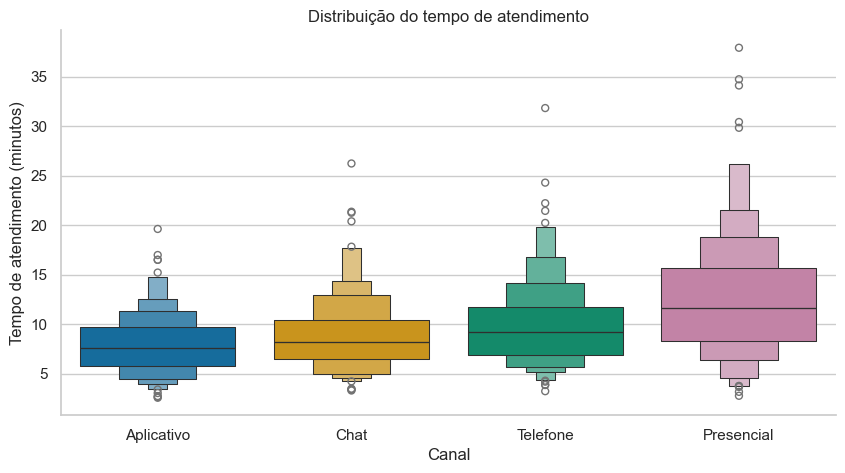

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxenplot(
    data=atendimentos, x="canal", y="tempo_min",
    order=canais, palette=PALETA, ax=ax
)
ax.set(
    title="Distribuição do tempo de atendimento",
    xlabel="Canal", ylabel="Tempo de atendimento (minutos)"
)
sns.despine()
plt.show()

## 3. Swarmplot — pontos empacotados

O `swarmplot` desloca cada ponto apenas o necessário para evitar sobreposição. Assim, preserva os valores individuais e comunica a densidade.

Plotly oferece `strip`, mas não o algoritmo de empacotamento do beeswarm. Em Altair, seria necessário calcular ou simular o deslocamento.

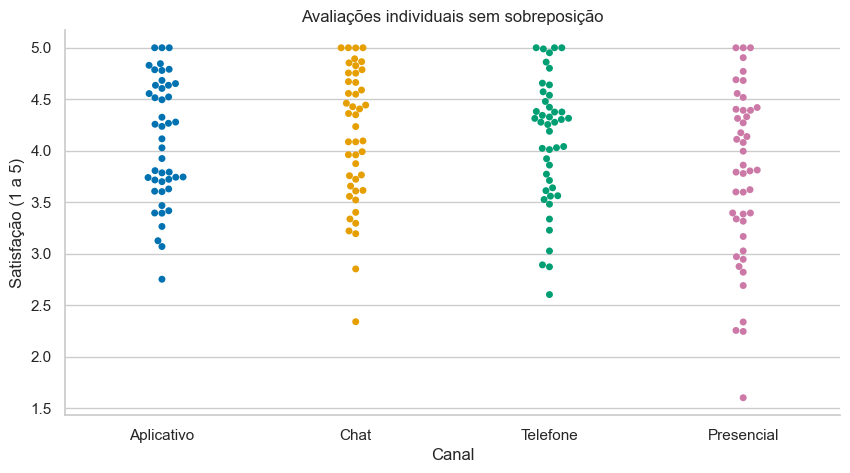

In [5]:
amostra = atendimentos.groupby("canal", group_keys=False).sample(n=45, random_state=7)

fig, ax = plt.subplots(figsize=(10, 5))
sns.swarmplot(
    data=amostra, x="canal", y="satisfacao", hue="canal",
    order=canais, hue_order=canais, palette=PALETA, dodge=False, size=5, ax=ax
)
if ax.legend_ is not None:
    ax.legend_.remove()
ax.set(
    title="Avaliações individuais sem sobreposição",
    xlabel="Canal", ylabel="Satisfação (1 a 5)"
)
sns.despine()
plt.show()

## 4. Pointplot — estimativa e incerteza

O `pointplot` calcula uma estimativa por grupo e seu intervalo de confiança por bootstrap. A linha ajuda a comparar o padrão entre categorias.

Nas outras bibliotecas, é necessário calcular as estimativas e os intervalos antes de desenhá-los ou recorrer a funções auxiliares.

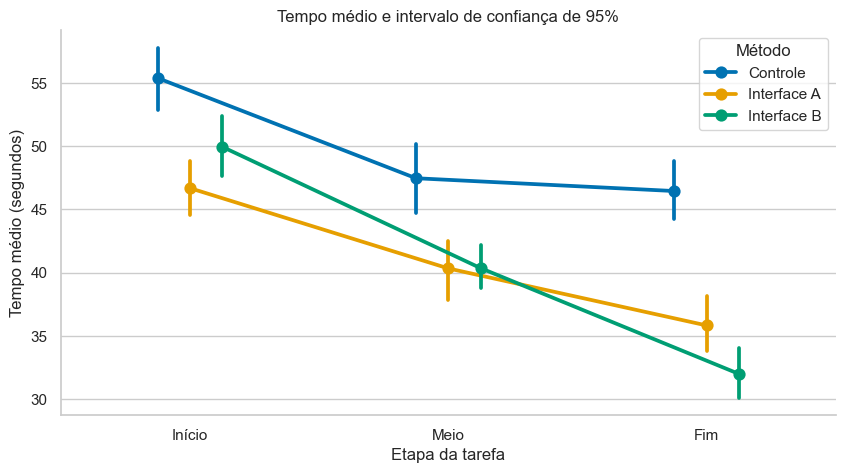

In [6]:
experimento = pd.DataFrame({
    "metodo": np.repeat(["Controle", "Interface A", "Interface B"], 90),
    "etapa": np.tile(np.repeat(["Início", "Meio", "Fim"], 30), 3),
    "tempo_s": np.concatenate([
        rng.normal(52, 8, 30), rng.normal(48, 7, 30), rng.normal(45, 7, 30),
        rng.normal(48, 7, 30), rng.normal(41, 6, 30), rng.normal(36, 6, 30),
        rng.normal(50, 7, 30), rng.normal(39, 6, 30), rng.normal(32, 5, 30)
    ])
})

versao = tuple(int(parte) for parte in sns.__version__.split(".")[:2])
intervalo = {"errorbar": ("ci", 95)} if versao >= (0, 12) else {"ci": 95}

fig, ax = plt.subplots(figsize=(10, 5))
sns.pointplot(
    data=experimento, x="etapa", y="tempo_s", hue="metodo",
    order=["Início", "Meio", "Fim"], dodge=0.25,
    palette=PALETA[:3], ax=ax, **intervalo
)
ax.set(
    title="Tempo médio e intervalo de confiança de 95%",
    xlabel="Etapa da tarefa", ylabel="Tempo médio (segundos)"
)
ax.legend(title="Método")
sns.despine()
plt.show()

## 5. Residplot — diagnóstico de uma relação

O `residplot` ajusta uma regressão e mostra os resíduos em torno de zero. Padrões curvos, mudanças de dispersão ou grupos separados sugerem que o modelo linear não descreve toda a estrutura.

Altair e Plotly podem desenhar resíduos, mas não possuem uma função nativa que ajuste o modelo e produza diretamente este diagnóstico.

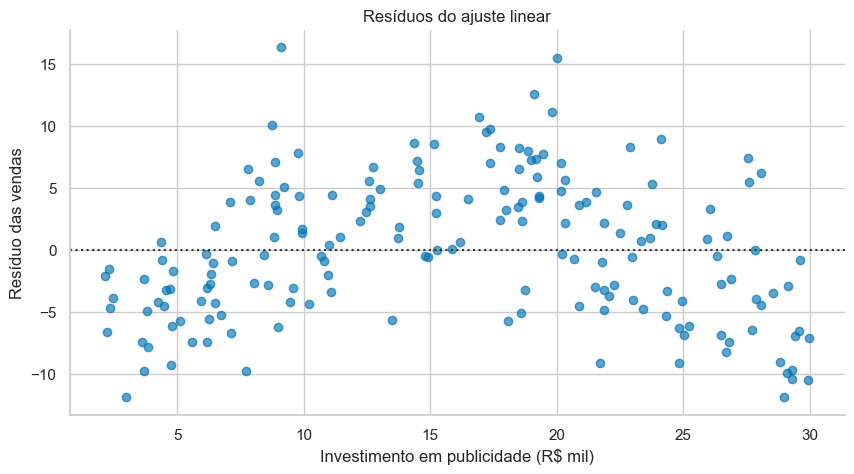

In [7]:
publicidade = rng.uniform(2, 30, 180)
vendas = 18 + 3.1*publicidade - 0.055*publicidade**2 + rng.normal(0, 5, 180)
campanhas = pd.DataFrame({"publicidade_mil": publicidade, "vendas_mil": vendas})

fig, ax = plt.subplots(figsize=(10, 5))
sns.residplot(
    data=campanhas, x="publicidade_mil", y="vendas_mil",
    scatter_kws={"alpha": 0.65, "color": "#0072B2"},
    line_kws={"color": "#D55E00"}, ax=ax
)
ax.set(
    title="Resíduos do ajuste linear",
    xlabel="Investimento em publicidade (R$ mil)", ylabel="Resíduo das vendas"
)
sns.despine()
plt.show()

## 6. Clustermap — mapa de calor com agrupamento

O `clustermap` calcula distâncias, executa agrupamento hierárquico, reordena linhas e colunas e acrescenta dendrogramas.

Altair não realiza agrupamento hierárquico. Plotly oferece componentes para heatmap e dendrograma, mas não uma função nativa única equivalente ao `clustermap`.

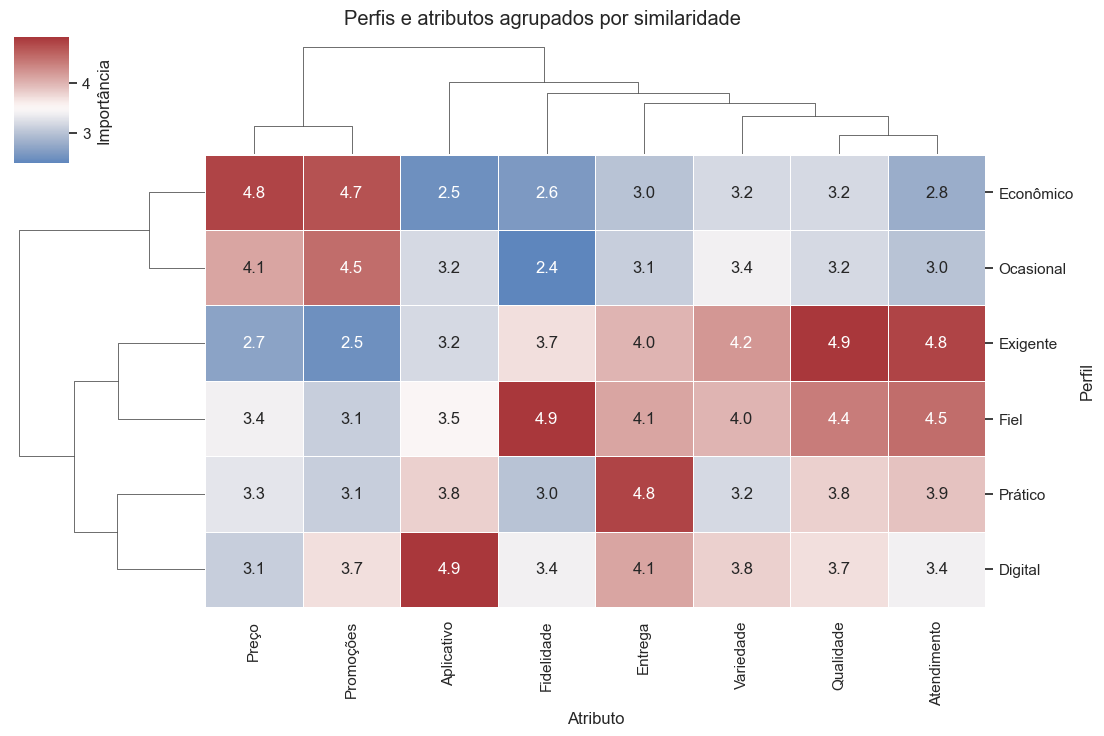

In [8]:
segmentos = ["Preço", "Qualidade", "Entrega", "Atendimento", "Variedade", "Aplicativo", "Fidelidade", "Promoções"]
perfis = ["Econômico", "Prático", "Digital", "Exigente", "Fiel", "Ocasional"]
base = np.array([
    [4.8, 3.2, 3.0, 2.8, 3.2, 2.5, 2.6, 4.7],
    [3.3, 3.8, 4.8, 3.9, 3.2, 3.8, 3.0, 3.1],
    [3.1, 3.7, 4.1, 3.4, 3.8, 4.9, 3.4, 3.7],
    [2.7, 4.9, 4.0, 4.8, 4.2, 3.2, 3.7, 2.5],
    [3.4, 4.4, 4.1, 4.5, 4.0, 3.5, 4.9, 3.1],
    [4.1, 3.2, 3.1, 3.0, 3.4, 3.2, 2.4, 4.5]
])
preferencias = pd.DataFrame(base, index=perfis, columns=segmentos)

g = sns.clustermap(
    preferencias, cmap="vlag", center=3.5, annot=True, fmt=".1f",
    linewidths=0.5, figsize=(11, 7), cbar_kws={"label": "Importância"}
)
g.fig.suptitle("Perfis e atributos agrupados por similaridade", y=1.02)
g.ax_heatmap.set(xlabel="Atributo", ylabel="Perfil")
plt.show()

## Síntese

| Necessidade | Função do Seaborn | O que a função resolve |
|---|---|---|
| Examinar caudas com muitos dados | `boxenplot` | Calcula e representa valores-letra |
| Mostrar observações sem sobreposição | `swarmplot` | Calcula o empacotamento dos pontos |
| Comparar estimativas e incerteza | `pointplot` | Agrega e estima intervalos por bootstrap |
| Diagnosticar um ajuste linear | `residplot` | Ajusta o modelo e calcula resíduos |
| Descobrir grupos em uma matriz | `clustermap` | Agrupa, reordena e desenha dendrogramas |

**Mensagem principal:** a principal diferença do Seaborn não é uma nova marca gráfica, mas a integração entre cálculo estatístico e visualização. Sempre documente a estimativa, o intervalo e o método de agrupamento utilizados.

### Referências

- [Documentação do Seaborn](https://seaborn.pydata.org/)
- [Visualizações categóricas](https://seaborn.pydata.org/tutorial/categorical.html)
- [Visualização de modelos de regressão](https://seaborn.pydata.org/tutorial/regression.html)
- [Documentação do clustermap](https://seaborn.pydata.org/generated/seaborn.clustermap.html)